# Orderbook Analysis

Predict 10-second mid-price returns from quotes and trades.

Asset IDs are pseudonyms. The calendar date is shifted; intraday timing is preserved.

**Main results**

- Random forest lowers test RMSE by **5.05%** versus zero.
- Zero has the lowest MAE.
- One day of data; 49 stocks in the test set.

## 1. Rough data analysis

50 stocks, one day. Quotes contain the best bid/ask; trades contain executions.

- Time: Shanghai (UTC+8); source timestamps are Unix microseconds.
- Units assumed: CNY and shares.
- Sessions: 09:30–11:30 and 13:00–15:00.
- Inputs: `data/market_quotes.csv.gz` and `data/market_trades.csv.gz`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

DATA_DIR = 'data/'
FOCUS = 'asset_001'
HORIZON = 10                       # forecast horizon in seconds
MAX_QUOTE_AGE = 5                  # reject stale snapshots in the model
MAX_PRICE = 1_000_000             # broad sanity limits for this dataset
MAX_SIZE = 1_000_000_000
SEED = 42

BLUE, GOLD, GREY = '#2455a4', '#bb7916', '#596273'
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .15,
                     'figure.dpi': 120, 'savefig.bbox': 'tight'})

### Load data

In [2]:
raw_quote = pd.read_csv(DATA_DIR + 'market_quotes.csv.gz', dtype={'symbol': 'category'})
raw_trade = pd.read_csv(DATA_DIR + 'market_trades.csv.gz', dtype={'symbol': 'category'})

### Quotes

In [3]:
display(raw_quote.head(3))
print('Rows, columns:', raw_quote.shape)
print('Stocks:', raw_quote['symbol'].nunique())
print('Missing cells:', raw_quote.isna().sum().sum()) # first sum is per col, second is total 
print('Non-finite:', (~np.isfinite(raw_quote.select_dtypes('number'))).sum().sum())
print('Exact duplicates:', raw_quote.duplicated().sum())
print('Repeated stock/time:', raw_quote.duplicated(['symbol', 'recv_time']).sum())
display(raw_quote[['bid_price', 'bid_size', 'ask_price', 'ask_size']].describe().T)
display(raw_quote.loc[raw_quote.duplicated(['symbol', 'recv_time'], keep=False)].head(3)) # keep=False keeps every row in a duplicated group

,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
0,946862100046531,asset_027,11.25,382800,0.0,0
1,946862100052041,asset_040,2.41,154800,0.0,0
2,946862100053790,asset_035,0.00,0,19.0,400


Rows, columns: (1312745, 6)
Stocks: 50
Missing cells: 0
Non-finite: 0
Exact duplicates: 0
Repeated stock/time: 96237


,count,mean,std,min,25%,50%,75%,max
bid_price,1312745.0,7658.014088,8.727901e+06,0.0,10.67,16.04,56.42,1.000000e+10
bid_size,1312745.0,51581.423134,1.854745e+05,-100000.0,1300.00,6500.00,27667.00,3.864600e+06
ask_price,1312745.0,7657.961092,8.727901e+06,0.0,10.68,16.03,56.31,1.000000e+10
ask_size,1312745.0,83443.314539,4.110124e+05,-100000.0,1200.00,5900.00,28000.00,6.773600e+06


,recv_time,symbol,bid_price,bid_size,ask_price,ask_size
265,946862700226860,asset_007,10.59,11600,10.6,26100
266,946862700226860,asset_007,10.59,11600,10.6,23188
271,946862700257135,asset_010,4.57,2600,4.6,15600


### Trades

In [4]:
display(raw_trade.head(3))
print('Rows, columns:', raw_trade.shape)
print('Stocks:', raw_trade['symbol'].nunique())
print('Missing cells:', raw_trade.isna().sum().sum())
print('Non-finite:', (~np.isfinite(raw_trade.select_dtypes('number'))).sum().sum())
print('Exact duplicates:', raw_trade.duplicated().sum())
print('Repeated stock/time:', raw_trade.duplicated(['symbol', 'recv_time']).sum())
display(raw_trade[['trade_price', 'trade_qty']].describe().T)
display(raw_trade.loc[raw_trade.duplicated(['symbol', 'recv_time'], keep=False)].head(3))

,recv_time,symbol,trade_price,trade_qty
0,946862700206666,asset_003,15.64,100
1,946862700206668,asset_003,15.64,2900
2,946862700206670,asset_003,15.64,1500


Rows, columns: (1158474, 4)
Stocks: 50
Missing cells: 0
Non-finite: 0
Exact duplicates: 9
Repeated stock/time: 92


,count,mean,std,min,25%,50%,75%,max
trade_price,1158474.0,128.512611,9.290882e+04,-100000.0,10.74,20.59,56.69,1.000000e+08
trade_qty,1158474.0,87412.417429,9.290880e+07,-100000.0,100.00,300.00,800.00,1.000000e+11


,recv_time,symbol,trade_price,trade_qty
1340,946862700225772,asset_006,13.95,100
1341,946862700225772,asset_006,13.95,900
1460,946862700226856,asset_007,10.60,3400


### Check time coverage

Preserve file order when timestamps tie.

In [5]:
quote_raw = raw_quote.copy()
quote_raw['row_order'] = np.arange(len(quote_raw))
quote_raw['time'] = pd.to_datetime(quote_raw['recv_time'], unit='us', utc=True)
quote_raw['time'] = quote_raw['time'].dt.tz_convert('Asia/Shanghai')
quote_raw = quote_raw.sort_values(['time', 'row_order'], kind='stable')

trade_raw = raw_trade.copy()
trade_raw['row_order'] = np.arange(len(trade_raw))
trade_raw['time'] = pd.to_datetime(trade_raw['recv_time'], unit='us', utc=True)
trade_raw['time'] = trade_raw['time'].dt.tz_convert('Asia/Shanghai')
trade_raw = trade_raw.sort_values(['time', 'row_order'], kind='stable')

# Check if all the rows come from the same day.
day = quote_raw['time'].iloc[0].normalize()
assert quote_raw['time'].dt.normalize().eq(day).all()
assert trade_raw['time'].dt.normalize().eq(day).all()
print('Date:', day.date())

Date: 2000-01-03


### Trading hours

In [6]:
# Add the date to each session's start and end time.
morning_start = day + pd.Timedelta('9h30min')
morning_end = day + pd.Timedelta('11h30min')
afternoon_start = day + pd.Timedelta('13h')
afternoon_end = day + pd.Timedelta('15h')
opening_end = day + pd.Timedelta('10h')
SESSION_BOUNDS = [(morning_start, morning_end), (afternoon_start, afternoon_end)]

In [7]:
quote_coverage = quote_raw.groupby('symbol', observed=True)['time'].agg(['size', 'min', 'max'])
print('Quotes per stock:')
display(quote_coverage['size'].agg(['min', 'median', 'max']).to_frame('rows')) # converts a Series into a one-column DataFrame, naming the column rows
display(quote_coverage.head(3))

Quotes per stock:


,rows
min,1685.0
median,18356.0
max,81491.0


,size,min,max
symbol,,,
asset_001,29008,2000-01-03 09:15:00.105593+08:00,2000-01-03 15:00:00.453455+08:00
asset_002,50250,2000-01-03 09:15:00.096678+08:00,2000-01-03 15:00:00.489842+08:00
asset_003,57951,2000-01-03 09:15:00.067511+08:00,2000-01-03 15:00:00.463939+08:00


In [8]:
trade_coverage = trade_raw.groupby('symbol', observed=True)['time'].agg(['size', 'min', 'max'])
print('Trades per stock:')
display(trade_coverage['size'].agg(['min', 'median', 'max']).to_frame('rows'))
display(trade_coverage.head(3))

Trades per stock:


,rows
min,1143.0
median,16410.5
max,76169.0


,size,min,max
symbol,,,
asset_001,25354,2000-01-03 09:25:00.426298+08:00,2000-01-03 15:00:00.453455+08:00
asset_002,46213,2000-01-03 09:25:00.480765+08:00,2000-01-03 15:00:00.489842+08:00
asset_003,54560,2000-01-03 09:25:00.206666+08:00,2000-01-03 15:00:00.463939+08:00


## 2. Data cleaning

Apply the same checks to all rows. Limits are specific to this dataset.

- Drop missing, non-finite and nonpositive values.
- Drop crossed quotes; keep locked quotes.
- Flag prices above 1 million CNY or sizes above 1 billion shares.
- Remove exact trade repeats (assumption: no trade IDs).
- Keep 09:30–15:00. Counts below may overlap.

### Quotes

In [9]:
quote_values = quote_raw[['bid_price', 'ask_price', 'bid_size', 'ask_size']]
quote_flags = pd.DataFrame(index=quote_raw.index)
quote_flags['missing / non-finite'] = quote_raw.isna().any(axis=1) | ~np.isfinite(
    quote_raw[['recv_time', 'bid_price', 'ask_price', 'bid_size', 'ask_size']]).all(axis=1)
quote_flags['nonpositive price / size'] = (quote_values <= 0).any(axis=1)
quote_flags['extreme price'] = (quote_values[['bid_price', 'ask_price']] > MAX_PRICE).any(axis=1)
quote_flags['extreme size'] = (quote_values[['bid_size', 'ask_size']] > MAX_SIZE).any(axis=1)
quote_flags['crossed quote'] = quote_raw['bid_price'] > quote_raw['ask_price']

display(quote_flags.sum().to_frame('rows'))
display(quote_raw.loc[quote_flags['extreme price'] | quote_flags['extreme size'],
    ['symbol', 'time', 'bid_price', 'ask_price', 'bid_size', 'ask_size']].head(3))

,rows
missing / non-finite,0
nonpositive price / size,1562
extreme price,2
extreme size,0
crossed quote,1509


,symbol,time,bid_price,ask_price,bid_size,ask_size
1864,asset_001,2000-01-03 09:30:01.103758+08:00,1.000000e+10,2.120000e+01,9900,10500
2031,asset_001,2000-01-03 09:30:01.221329+08:00,2.119000e+01,1.000000e+10,24500,10500


### Trades

In [10]:
trade_values = trade_raw[['trade_price', 'trade_qty']]
trade_flags = pd.DataFrame(index=trade_raw.index)
trade_flags['missing / non-finite'] = trade_raw.isna().any(axis=1) | ~np.isfinite(
    trade_raw[['recv_time', 'trade_price', 'trade_qty']]).all(axis=1)
trade_flags['nonpositive price / size'] = (trade_values <= 0).any(axis=1)
trade_flags['extreme price'] = trade_values['trade_price'] > MAX_PRICE
trade_flags['extreme size'] = trade_values['trade_qty'] > MAX_SIZE

display(trade_flags.sum().to_frame('rows'))
display(trade_raw.loc[trade_flags['extreme price'] | trade_flags['extreme size'],
    ['symbol', 'time', 'trade_price', 'trade_qty']].head(3))

,rows
missing / non-finite,0
nonpositive price / size,2
extreme price,1
extreme size,1


,symbol,time,trade_price,trade_qty
4693,asset_001,2000-01-03 09:25:00.426319+08:00,99999999.00,100
4701,asset_001,2000-01-03 09:25:00.426329+08:00,21.12,99999999999


### Apply cleaning rules

In [11]:
quote = quote_raw.loc[~quote_flags.any(axis=1)].copy()
trade_before_dedup = trade_raw.loc[~trade_flags.any(axis=1)].copy()
trade = trade_before_dedup.drop_duplicates(subset=raw_trade.columns.tolist()).copy()

quote_in_window = quote['time'].between(morning_start, afternoon_end)
trade_in_window = trade['time'].between(morning_start, afternoon_end)
cleaning = pd.DataFrame({
    'quote': [len(quote_raw), len(quote), len(quote), quote_in_window.sum()],
    'trade': [len(trade_raw), len(trade_before_dedup), len(trade), trade_in_window.sum()]
}, index=['raw rows', 'after validity checks', 'after exact-repeat policy', 'within 09:30–15:00'])
display(cleaning)

removed_volume = trade_before_dedup['trade_qty'].sum() - trade['trade_qty'].sum()
removed_fraction = removed_volume / trade_before_dedup['trade_qty'].sum()
print(f'Duplicate trades removed: {removed_volume:,.0f} shares ({removed_fraction:.6%}).')

quote = quote.loc[quote_in_window].copy()
trade = trade.loc[trade_in_window].copy()
quote['spread'] = quote['ask_price'] - quote['bid_price']
quote['mid'] = (quote['bid_price'] + quote['ask_price']) / 2
assert (quote['spread'] >= 0).all()
assert set(trade['symbol']) == set(quote['symbol'])

,quote,trade
raw rows,1312745,1158474
after validity checks,1311181,1158470
after exact-repeat policy,1311181,1158461
within 09:30–15:00,1310862,1138623


Duplicate trades removed: 1,700 shares (0.000134%).


### Check gaps

Keep lunch and missing quotes separate from zero trading volume.

In [12]:
# -1: outside the model's sessions; 0: morning; 1: afternoon.
quote['session'] = -1
quote.loc[quote['time'].between(morning_start, morning_end, inclusive='left'), 'session'] = 0
quote.loc[quote['time'].between(afternoon_start, afternoon_end, inclusive='left'), 'session'] = 1

trade['session'] = -1
trade.loc[trade['time'].between(morning_start, morning_end, inclusive='left'), 'session'] = 0
trade.loc[trade['time'].between(afternoon_start, afternoon_end, inclusive='left'), 'session'] = 1

quote_gaps = quote.sort_values(['symbol', 'session', 'time', 'row_order']).copy()
quote_gaps['gap_s'] = quote_gaps.groupby(['symbol', 'session'], observed=True)['time'].diff().dt.total_seconds()
gap_summary = quote_gaps.groupby('symbol', observed=True).agg(
    quotes=('time', 'size'), first=('time', 'min'), last=('time', 'max'), max_gap_s=('gap_s', 'max'))
display(gap_summary.nlargest(5, 'max_gap_s'))
print('Outside model sessions:', (quote['session'] < 0).sum(), 'quotes,',
      (trade['session'] < 0).sum(), 'trades')

early_ends = quote.groupby('symbol', observed=True)['time'].max()
early_ends = early_ends.loc[early_ends < day + pd.Timedelta('14h50min')]
display(early_ends.to_frame('last quote before 14:50'))
print('Do not fill prices after a stock stops quoting.')

,quotes,first,last,max_gap_s
symbol,,,,
asset_010,3067,2000-01-03 09:30:00.132068+08:00,2000-01-03 14:57:15.631402+08:00,106.337293
asset_018,1680,2000-01-03 09:30:00.208391+08:00,2000-01-03 14:56:58.799465+08:00,100.298838
asset_050,2076,2000-01-03 09:30:00.074634+08:00,2000-01-03 14:57:11.147010+08:00,97.989655
asset_047,9797,2000-01-03 09:30:00.155378+08:00,2000-01-03 13:13:24.281812+08:00,94.385581
asset_044,6653,2000-01-03 09:30:00.131500+08:00,2000-01-03 14:56:58.201075+08:00,82.824500


Outside model sessions: 0 quotes, 0 trades


,last quote before 14:50
symbol,
asset_047,2000-01-03 13:13:24.281812+08:00


Do not fill prices after a stock stops quoting.


## 3. EDA

Start the time split here: first 60% for training, last 40% for testing.
Full-day summaries answer the descriptive questions. Predictive exploration uses training data only.

### Split by time

In [13]:
# Create one timestamp per trading second, excluding lunch and session ends.
morning_clock = pd.date_range(morning_start, morning_end, freq='1s', inclusive='left')
afternoon_clock = pd.date_range(afternoon_start, afternoon_end, freq='1s', inclusive='left')
clock = morning_clock.append(afternoon_clock)
TEST_START = clock[int(.60 * len(clock))]
print('Test starts:', TEST_START.strftime('%H:%M:%S'))

Test starts: 13:24:00


In [14]:
clock

DatetimeIndex(['2000-01-03 09:30:00+08:00', '2000-01-03 09:30:01+08:00',
               '2000-01-03 09:30:02+08:00', '2000-01-03 09:30:03+08:00',
               '2000-01-03 09:30:04+08:00', '2000-01-03 09:30:05+08:00',
               '2000-01-03 09:30:06+08:00', '2000-01-03 09:30:07+08:00',
               '2000-01-03 09:30:08+08:00', '2000-01-03 09:30:09+08:00',
               ...
               '2000-01-03 14:59:50+08:00', '2000-01-03 14:59:51+08:00',
               '2000-01-03 14:59:52+08:00', '2000-01-03 14:59:53+08:00',
               '2000-01-03 14:59:54+08:00', '2000-01-03 14:59:55+08:00',
               '2000-01-03 14:59:56+08:00', '2000-01-03 14:59:57+08:00',
               '2000-01-03 14:59:58+08:00', '2000-01-03 14:59:59+08:00'],
              dtype='datetime64[us, Asia/Shanghai]', length=14400, freq=None)

### Opening VWAP: 09:30–10:00

Both endpoints included.

$$\mathrm{VWAP}=\frac{\sum P_jQ_j}{\sum Q_j}.$$

In [15]:
opening = trade.loc[(trade['time'] >= morning_start) & (trade['time'] <= opening_end)].copy()
opening['notional'] = opening['trade_price'] * opening['trade_qty']

by_stock = opening.groupby('symbol', observed=True)
vwap = pd.DataFrame()
vwap['notional'] = by_stock['notional'].sum()
vwap['shares'] = by_stock['trade_qty'].sum()
vwap['trades'] = by_stock.size()
vwap['VWAP_CNY'] = vwap['notional'] / vwap['shares']

vwap = vwap.sort_values('VWAP_CNY', ascending=False)
display(vwap[['VWAP_CNY', 'shares', 'trades']].head(10))
vwap_winner = vwap.index[0]
print('Highest opening VWAP:', vwap_winner)

,VWAP_CNY,shares,trades
symbol,,,
asset_016,224.514342,4683281,16274
asset_031,162.962277,1328539,5860
asset_043,97.522274,3823036,7892
asset_013,84.885236,4378232,12257
asset_002,73.687979,7116911,11795
asset_047,61.763589,187169,867
asset_048,60.280759,1169411,3472
asset_034,57.253144,11192145,17686
asset_030,55.387437,5105515,13353


Highest opening VWAP: asset_016


### Volume by 30-minute interval

Include lunch intervals. Zero volume means no leader.

In [16]:
# stock names
symbols = sorted(quote['symbol'].unique())
# create time labels
wall_minutes = pd.date_range(morning_start, afternoon_end, freq='1min', inclusive='left')
half_hours = pd.date_range(morning_start, afternoon_end, freq='30min', inclusive='left')

trade['bucket_time'] = trade['time'].clip(upper=afternoon_end - pd.Timedelta('1us'))
# assig each trade to its window
trade['minute'] = trade['bucket_time'].dt.floor('1min')
trade['half_hour'] = trade['bucket_time'].dt.floor('30min')
# sum shares for each stock in each window
volume_30m = trade.groupby(['half_hour', 'symbol'], observed=True)['trade_qty'].sum().unstack('symbol') # unstack: turns stock names into columns
volume_30m = volume_30m.reindex(index=half_hours, columns=symbols).fillna(0)

leaders = []
for time, row in volume_30m.iterrows():
    peak = row.max()
    if peak > 0:
        names = row.idxmax()
    else:
        names = 'No recorded trades'
    leaders.append({'window': f'{time:%H:%M}–{time + pd.Timedelta("30min"):%H:%M}',
                    'leader': names, 'leader shares': peak, 'total shares': row.sum()})
leaders = pd.DataFrame(leaders)
display(leaders)

,window,leader,leader shares,total shares
0,09:30–10:00,asset_040,101160467.0,430038116.0
1,10:00–10:30,asset_040,49700140.0,201595422.0
2,10:30–11:00,asset_040,20134980.0,139818579.0
3,11:00–11:30,asset_040,20923687.0,96352224.0
4,11:30–12:00,No recorded trades,0.0,0.0
5,12:00–12:30,No recorded trades,0.0,0.0
6,12:30–13:00,No recorded trades,0.0,0.0
7,13:00–13:30,asset_040,12440400.0,91274801.0
8,13:30–14:00,asset_040,7673800.0,70814022.0
9,14:00–14:30,asset_040,10989000.0,83104121.0


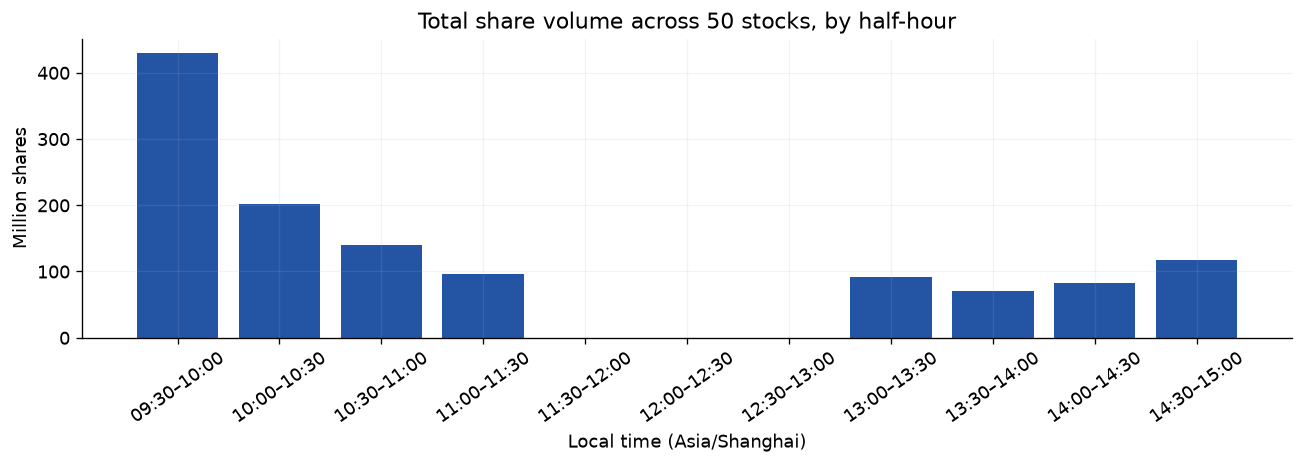

Busiest: 09:30–10:00 | Quietest active: 13:30–14:00


In [17]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(leaders['window'], leaders['total shares'] / 1e6, color=BLUE)
ax.set(title='Total share volume across 50 stocks, by half-hour',
       xlabel='Local time (Asia/Shanghai)', ylabel='Million shares')
ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
plt.show()
active_windows = leaders.loc[leaders['total shares'] > 0]
print('Busiest:', active_windows.loc[active_windows['total shares'].idxmax(), 'window'],
      '| Quietest active:', active_windows.loc[active_windows['total shares'].idxmin(), 'window'])

*Each bar totals traded shares across all 50 stocks, in millions. The opening half-hour is busiest (about 430 million shares); 11:30–13:00 is lunch. The quietest active window is 13:30–14:00.*

### Top five stocks: volume and spread

Minute volume on the left; mean quote spread on the right. Axes differ; missing quotes stay blank.

,total shares
symbol,
asset_040,237798986
asset_027,88426408
asset_003,66382861
asset_006,58024665
asset_035,56576653


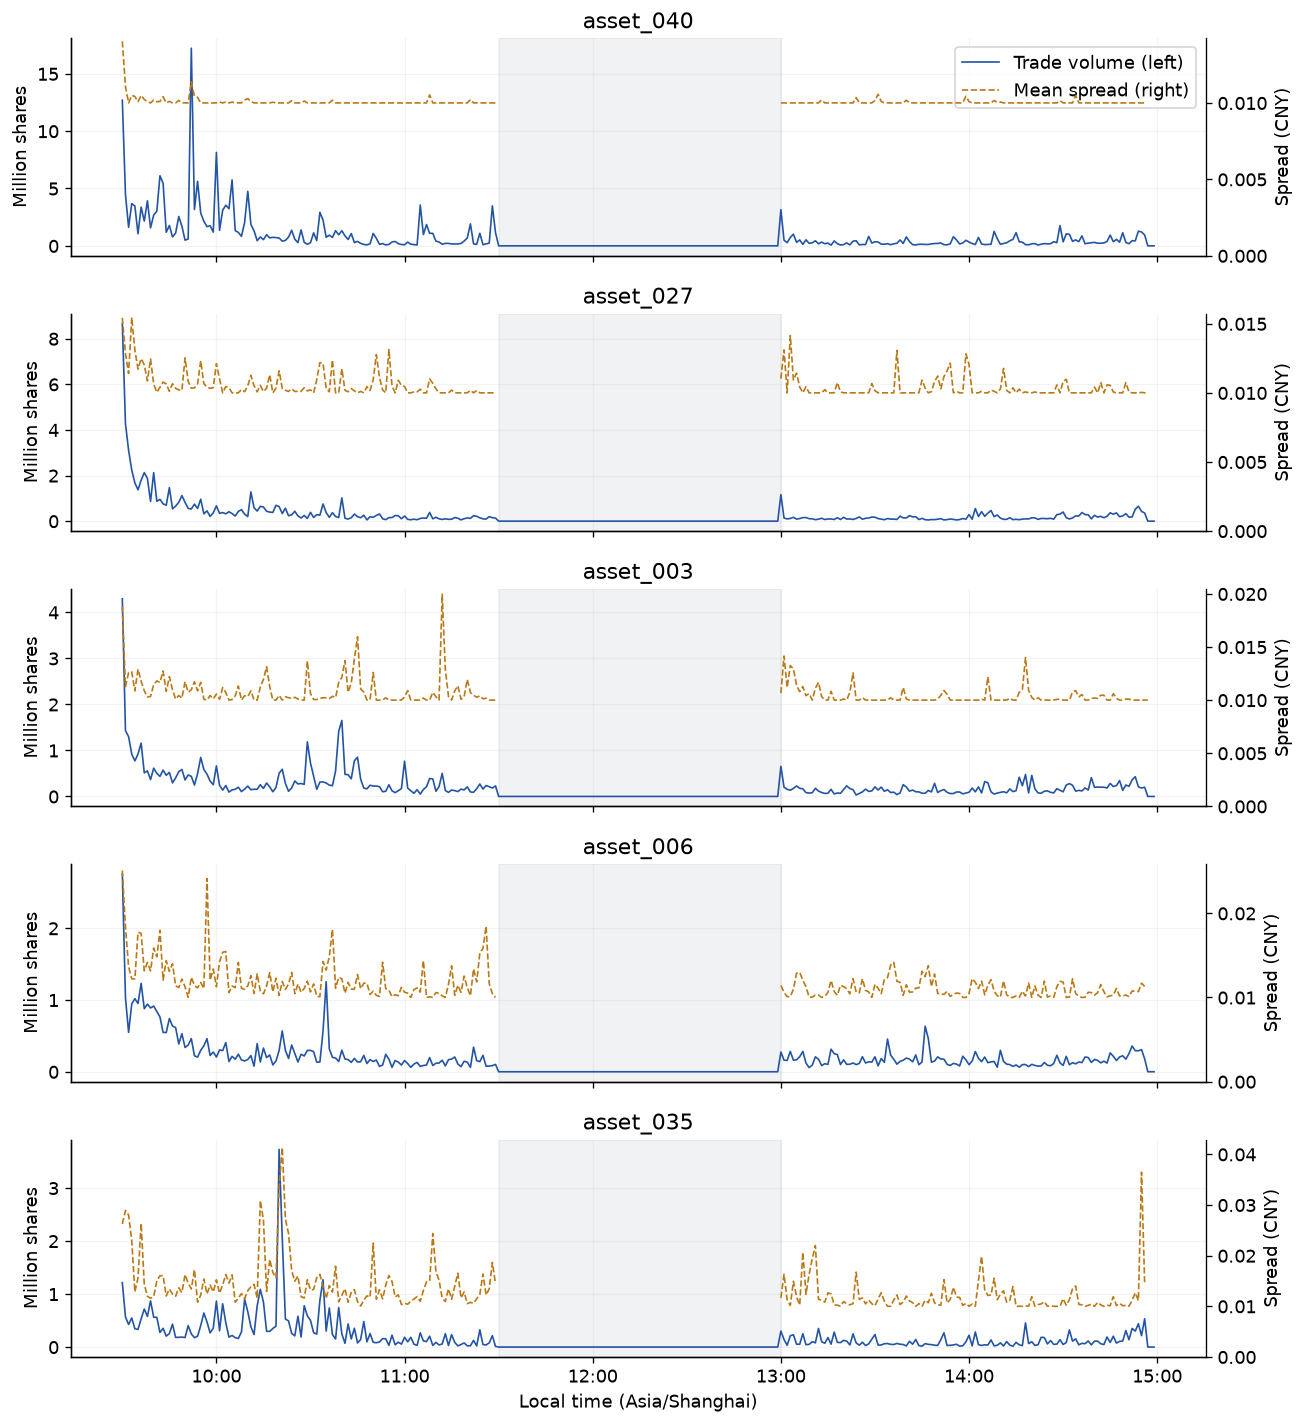

In [18]:
# find the five most active stocks
total_volume = trade.groupby('symbol', observed=True)['trade_qty'].sum().sort_values(ascending=False)
top5 = total_volume.head(5).index.tolist()
display(total_volume.head(5).rename('total shares').to_frame())

# calculate each stock's volume per minute
minute_volume = trade.groupby(['minute', 'symbol'], observed=True)['trade_qty'].sum().unstack('symbol')
minute_volume = minute_volume.reindex(index=wall_minutes, columns=top5).fillna(0)

# calculate each stock's mean spread per minute
quote['minute'] = quote['time'].clip(upper=afternoon_end - pd.Timedelta('1us')).dt.floor('1min')
minute_spread = quote.groupby(['minute', 'symbol'], observed=True)['spread'].mean().unstack('symbol')
minute_spread = minute_spread.reindex(index=wall_minutes, columns=top5)

fig, axes = plt.subplots(5, 1, figsize=(11, 12), sharex=True)
for ax, symbol in zip(axes, top5):
    left, = ax.plot(wall_minutes, minute_volume[symbol] / 1e6, color=BLUE, lw=1, label='Trade volume')
    ax.set(title=symbol, ylabel='Million shares')
    ax.axvspan(morning_end, afternoon_start, color=GREY, alpha=.08)
    right = ax.twinx()
    right.spines['right'].set_visible(True)
    line, = right.plot(wall_minutes, minute_spread[symbol], color=GOLD, ls='--', lw=1, label='Mean spread')
    right.set_ylabel('Spread (CNY)')
    right.grid(False)
    right.set_ylim(bottom=0)
axes[0].legend([left, line], ['Trade volume (left)', 'Mean spread (right)'], loc='upper right')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=day.tz))
axes[-1].set_xlabel('Local time (Asia/Shanghai)')
fig.tight_layout()
plt.show()

In [19]:
top5

['asset_040', 'asset_027', 'asset_003', 'asset_006', 'asset_035']

*Blue shows minute volume on the left axis; dashed gold shows mean bid–ask spread on the right. All five stocks are most active near the open. Grey shading marks lunch; the two axes have different units.*

### Volume correlations

Use active five-minute intervals. Compare raw volumes with session-demeaned volumes. One day cannot establish stable clusters.

In [20]:
morning_5m = pd.date_range(morning_start, morning_end, freq='5min', inclusive='left')
afternoon_5m = pd.date_range(afternoon_start, afternoon_end, freq='5min', inclusive='left')
five_minutes = morning_5m.append(afternoon_5m)

trade['five_minute'] = trade['bucket_time'].dt.floor('5min')
volume_5m = trade.groupby(['five_minute', 'symbol'], observed=True)['trade_qty'].sum().unstack('symbol')
volume_5m = volume_5m.reindex(index=five_minutes, columns=top5).fillna(0)
volume_corr = volume_5m.corr()

session_id = (volume_5m.index >= afternoon_start).astype(int)
session_mean_volume = volume_5m.groupby(session_id).transform('mean')
within_session_volume = volume_5m - session_mean_volume
session_corr = within_session_volume.corr()

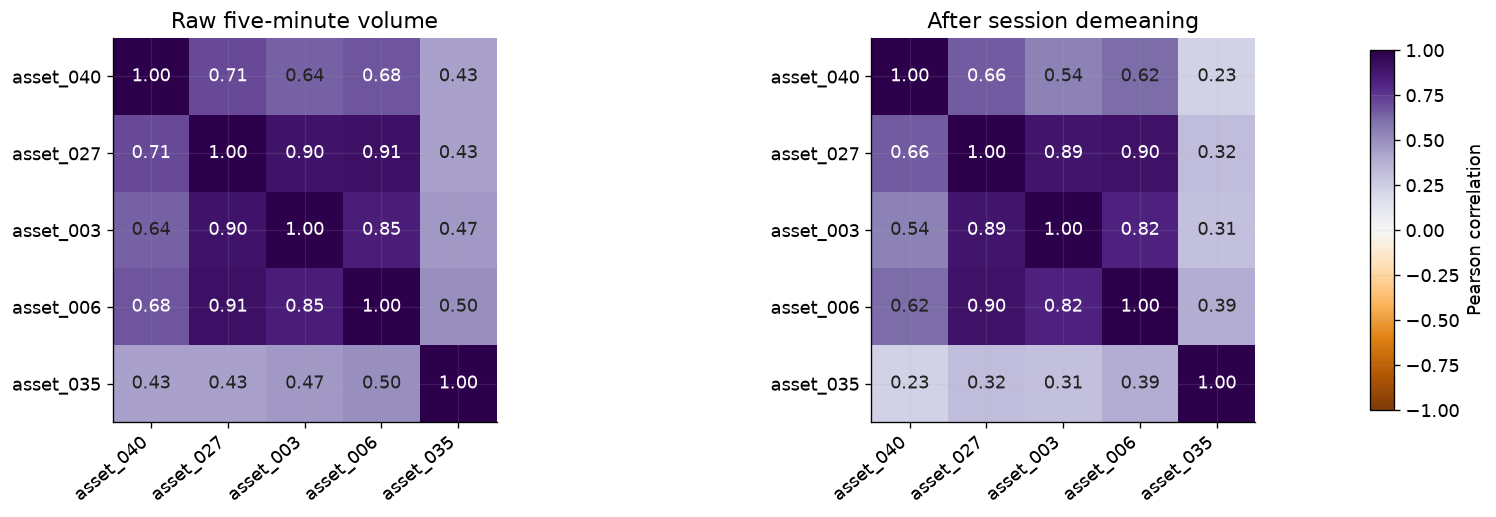

volume correlation
symbol    symbol                       
asset_027 asset_006            0.910901
          asset_003            0.896274
asset_003 asset_006            0.847940
asset_040 asset_027            0.705584
          asset_006            0.678781

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.subplots_adjust(left=.08, right=.88, bottom=.23, top=.87, wspace=.55)
matrices = [volume_corr, session_corr]
titles = ['Raw five-minute volume', 'After session demeaning']
for ax, matrix, title in zip(axes, matrices, titles):
    image = ax.imshow(matrix, vmin=-1, vmax=1, cmap='PuOr')
    ax.set_xticks(range(5), top5, rotation=40, ha='right')
    ax.set_yticks(range(5), top5)
    ax.set_title(title)
    for i in range(5):
        for j in range(5):
            color = 'white' if abs(matrix.iloc[i, j]) > .65 else '#222222'
            ax.text(j, i, f'{matrix.iloc[i, j]:.2f}', ha='center', va='center', color=color)
colorbar_axis = fig.add_axes([.92, .25, .015, .60])
fig.colorbar(image, cax=colorbar_axis, label='Pearson correlation')
plt.show()

# Rank each pair once, excluding the diagonal.
upper_triangle = np.triu(np.ones((5, 5), dtype=bool), k=1)
pair_corr = volume_corr.where(upper_triangle).stack().sort_values(ascending=False)
display(pair_corr.head(5).to_frame('volume correlation'))

*Each cell measures correlation between two stocks’ five-minute volumes; values near +1 mean activity moves together. The strongest pair is asset_027 / asset_006 (0.91). Their correlation remains high after removing session averages.*

To check whether the high correlation mainly comes from both stocks being busier in the morning and quieter in the afternoon.
After removing those average differences, we ask whether their five-minute fluctuations still move together.
In your data, the strongest pair stays around 0.90, so the relationship persists after this adjustment.

### Spread at quote and trade times

Match each trade to its latest same-session quote. Check match coverage, quote age and timestamp ties. These are quoted spreads.

In [22]:
focus_quote = quote.loc[(quote['symbol'] == FOCUS) & (quote['session'] >= 0)].copy()
focus_trade = trade.loc[(trade['symbol'] == FOCUS) & (trade['session'] >= 0)].copy()

quote_times = focus_quote[['symbol', 'session', 'time', 'spread', 'mid']].copy()
quote_times = quote_times.rename(columns={'time': 'quote_time'})

# Match each trade to the latest quote at or before it, within its session.
# the left dataframe will look backward for a quote in the right dataframe
aligned = pd.merge_asof(focus_trade, quote_times, left_on='time', right_on='quote_time',
                        by=['symbol', 'session'], direction='backward') 
aligned['quote_age_s'] = (aligned['time'] - aligned['quote_time']).dt.total_seconds()

# keeps only trades matched to a quote that is at most five seconds old
fresh = aligned.loc[aligned['quote_age_s'] <= MAX_QUOTE_AGE]

# Check whether excluding quotes at exactly the trade time changes the result.
strict_aligned = pd.merge_asof(focus_trade, quote_times, left_on='time', right_on='quote_time',
                               by=['symbol', 'session'], direction='backward', allow_exact_matches=False)

In [23]:
spread_comparison = pd.Series({
    'quote-update mean (CNY)': focus_quote['spread'].mean(),
    'quote-update sample std (CNY)': focus_quote['spread'].std(),
    'quote-update median (CNY)': focus_quote['spread'].median(),
    'trade-time mean (CNY)': aligned['spread'].mean(),
    'trade-time median (CNY)': aligned['spread'].median(),
    'fresh trade-time median (CNY)': fresh['spread'].median(),
    'strict-past trade-time median (CNY)': strict_aligned['spread'].median(),
    'matched fraction': aligned['spread'].notna().mean(),
    'matched within 5s fraction': aligned['quote_age_s'].le(MAX_QUOTE_AGE).mean()
})
display(spread_comparison.to_frame(FOCUS))
display(aligned['quote_age_s'].describe(percentiles=[.5, .9, .99]).to_frame('quote age (seconds)'))

,asset_001
quote-update mean (CNY),0.014337
quote-update sample std (CNY),0.008732
quote-update median (CNY),0.010000
trade-time mean (CNY),0.013427
trade-time median (CNY),0.010000
fresh trade-time median (CNY),0.010000
strict-past trade-time median (CNY),0.010000
matched fraction,0.999960
matched within 5s fraction,0.996845


,quote age (seconds)
count,25035.000000
mean,0.230200
std,0.641711
min,0.000000
50%,0.000000
90%,0.740716
99%,3.005803
max,9.733693


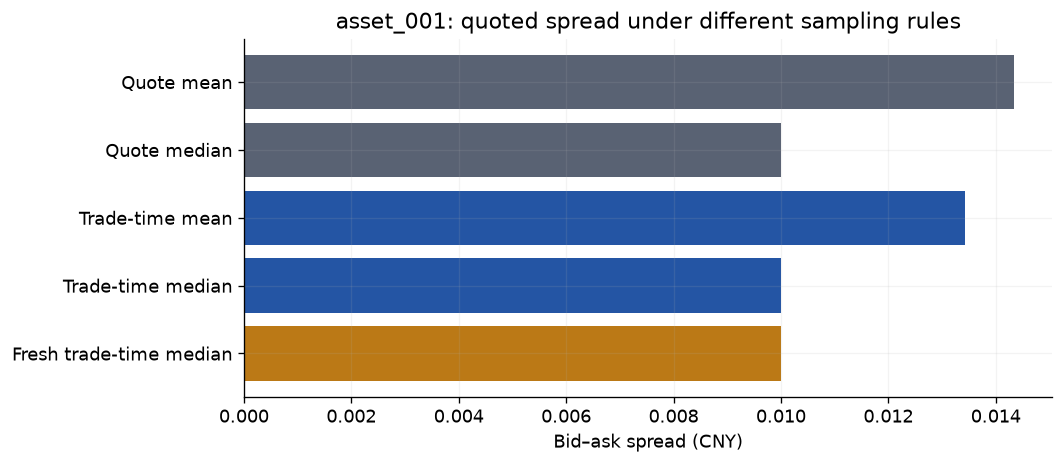

Mean and median use different summaries and sampling.


In [24]:
fig, ax = plt.subplots(figsize=(9, 4))
values = spread_comparison.iloc[[0, 2, 3, 4, 5]]
ax.barh(['Quote mean', 'Quote median', 'Trade-time mean', 'Trade-time median', 'Fresh trade-time median'],
        values.to_numpy(), color=[GREY, GREY, BLUE, BLUE, GOLD])
ax.set(title=f'{FOCUS}: quoted spread under different sampling rules', xlabel='Bid–ask spread (CNY)')
ax.invert_yaxis()
fig.tight_layout()
plt.show()
print('Mean and median use different summaries and sampling.')

*Longer bars mean wider bid–ask spreads. Medians are 0.01 CNY; higher means reflect occasional wider quotes. “Fresh” uses quotes received no more than five seconds before the trade.*

Quote spreads average **0.01434 CNY** (std **0.00873**), versus **0.01343 CNY** (std **0.00736**) at trade times. Both medians are **0.01 CNY**.

Trades tend to occur when spreads are narrower and less variable. Occasional wide spreads pull the means above the median.

### Trade direction

Uptick: +1. Downtick: −1. Unchanged: carry forward. Initial direction: unknown.

Reset direction at the start of each session. Tick direction only estimates aggressor side.

In [25]:
trade = trade.sort_values(['symbol', 'session', 'time', 'row_order'], kind='stable').copy() #kind='stable' rows with equal sorting values keep their original order

# Tick rule: a higher/lower trade price means buy/sell; carry the last sign for equal prices.
price_change = trade.groupby(['symbol', 'session'], observed=True)['trade_price'].diff()
trade['direction'] = np.sign(price_change).replace(0, np.nan) # sign converts positive changes to +1, negative changes to -1, and unchanged to 0
trade['direction'] = trade.groupby(['symbol', 'session'], observed=True)['direction'].ffill()

focus_trade = trade.loc[(trade['symbol'] == FOCUS) & (trade['session'] >= 0)].copy()
trade_directions = focus_trade[['row_order', 'direction']]
aligned = aligned.merge(trade_directions, on='row_order', how='left', validate='one_to_one')

# by default, value_counts() ignore NaNs, can use value_counts(dropna=False)
counts = focus_trade['direction'].fillna(0).value_counts().reindex([-1, 0, 1], fill_value=0)
direction_summary = pd.DataFrame({'trades': counts, 'fraction of all trades': counts / counts.sum()})
direction_summary.index = ['Seller tick', 'Unknown', 'Buyer tick']
classified = counts.loc[-1] + counts.loc[1]
direction_summary['fraction of classified'] = [counts.loc[-1] / classified, np.nan, counts.loc[1] / classified]
display(direction_summary)

# caluclate spread for buyer and seller-initiated trades
side_spread = aligned.groupby('direction')['spread'].agg(['count', 'mean', 'median'])
fresh_trades = aligned.loc[aligned['quote_age_s'] <= MAX_QUOTE_AGE]
side_spread['fresh mean'] = fresh_trades.groupby('direction')['spread'].mean()
display(side_spread.rename(index={-1: 'Seller tick', 1: 'Buyer tick'}))

,trades,fraction of all trades,fraction of classified
Seller tick,11206,0.447595,0.447685
Unknown,5,0.000200,NaN
Buyer tick,13825,0.552205,0.552315


,count,mean,median,fresh mean
direction,,,,
Seller tick,11206,0.013405,0.01,0.013409
Buyer tick,13825,0.013445,0.01,0.013434


Buy trades may occur more often when liquidity is thinner or prices are moving quickly, when spreads tend to be wider. Sellers may trade more often during quieter periods.

Tick-rule classification errors or random variation could also explain the gap. **The difference is only about 0.3%, so we cannot identify the cause from these averages alone.**

### Five-minute return tests

Use the first mid-price in each five-minute window. Exclude missing windows and lunch crossings.

Test mean log return = 0; apply Holm correction across stocks.

In [26]:
from scipy import stats

def holm_adjust(p_values):
    p = np.asarray(p_values)
    order = np.argsort(p)
    adjusted = np.empty(len(p))
    rank_adjusted = p[order] * (len(p) - np.arange(len(p)))
    adjusted[order] = np.minimum(1, np.maximum.accumulate(rank_adjusted))
    return adjusted

q5 = quote.loc[quote['session'] >= 0].sort_values(['time', 'row_order'], kind='stable').copy()
q5['bucket'] = q5['time'].dt.floor('5min')
# select the first quote in each five-minute interval
opens = q5.groupby(['symbol', 'session', 'bucket'], observed=True).first().reset_index() 


# pivot creates one column per stock and one row per window
# reindex includes every expected window, leaving missing prices as NaN
mid_open = opens.pivot(index='bucket', columns='symbol', values='mid').reindex(five_minutes)
next_mid = mid_open.shift(-1)
bucket_times = pd.Series(five_minutes, index=five_minutes)
# 11:25 to 13:00 fails this check
same_session = (bucket_times.shift(-1) - bucket_times).eq(pd.Timedelta('5min'))
returns_5m = np.log(next_mid / mid_open).where(same_session, axis=0)

# Test whether each stock's mean return is zero.
return_tests = returns_5m.agg(['count', 'mean', 'std']).T
return_tests = return_tests.rename(columns={'count': 'n'})
return_tests['n'] = return_tests['n'].astype(int)
return_tests['t'] = return_tests['mean'] / (return_tests['std'] / np.sqrt(return_tests['n']))
return_tests['p classical'] = 2 * stats.t.sf(return_tests['t'].abs(), df=return_tests['n'] - 1)
return_tests['p Holm'] = holm_adjust(return_tests['p classical'])

display(return_tests.round(5))
print('Significant after Holm:', return_tests.index[return_tests['p Holm'] < 0.05].tolist())

,n,mean,std,t,p classical,p Holm
symbol,,,,,,
asset_001,46,0.00037,0.00306,0.81321,0.42038,1.00000
asset_002,46,0.00003,0.00271,0.08515,0.93252,1.00000
asset_003,46,0.00015,0.00243,0.42605,0.67210,1.00000
asset_004,46,0.00030,0.00206,0.97687,0.33386,1.00000
asset_005,46,0.00006,0.00145,0.29915,0.76620,1.00000
asset_006,46,0.00043,0.00442,0.66275,0.51087,1.00000
asset_007,46,0.00059,0.00328,1.21281,0.23153,1.00000
asset_008,46,0.00033,0.00414,0.54395,0.58916,1.00000
asset_009,46,-0.00075,0.00455,-1.11708,0.26989,1.00000


Significant after Holm: ['asset_047']


## 4. Feature construction

One row per stock per second; 10 features predict the next 10-second return.

At time $t$, use the latest quote received at or before $t$, within the same session. Set prices and sizes to missing when the quote is over five seconds old.

Let $B_t,A_t$ be bid/ask prices, $Q_t^b,Q_t^a$ their sizes, and $\tau_t$ the quote timestamp. Mid-price and target are:

$$M_t=\frac{B_t+A_t}{2},\qquad y_t=10^4\log\left(\frac{M_{t+10}}{M_t}\right).$$

The target is a future return, not an input. One basis point is 0.01%. All shifts stay within each stock and session.

In [27]:
# Sample each stock and session separately; use only earlier quotes.
snapshots = []
active_quotes = quote.loc[quote['session'] >= 0]
quote_columns = ['quote_time', 'bid_price', 'ask_price', 'bid_size', 'ask_size']
for (symbol, session), stock_quotes in active_quotes.groupby(['symbol', 'session'], observed=True):
    start, end = SESSION_BOUNDS[session]
    grid = pd.DataFrame({'time': pd.date_range(start, end, freq='1s', inclusive='left')})
    stock_quotes = stock_quotes.sort_values(['time', 'row_order'], kind='stable')
    stock_quotes = stock_quotes.rename(columns={'time': 'quote_time'})
    sampled = pd.merge_asof(grid, stock_quotes[quote_columns], left_on='time',
                            right_on='quote_time', direction='backward')
    sampled['age_s'] = (sampled['time'] - sampled['quote_time']).dt.total_seconds()
    stale = sampled['age_s'] > MAX_QUOTE_AGE
    sampled.loc[stale, ['bid_price', 'ask_price', 'bid_size', 'ask_size']] = np.nan
    sampled['symbol'] = symbol
    sampled['session'] = session
    snapshots.append(sampled)

panel = pd.concat(snapshots, ignore_index=True)
panel = panel.sort_values(['symbol', 'session', 'time']).reset_index(drop=True)

### Returns and quote features

| Feature | Formula | Meaning |
|---|---|---|
| `return_1s_bps`, `return_5s_bps`, `return_10s_bps` | $10^4\log(M_t/M_{t-k}),\ k=1,5,10$ | Three past-return features |
| `spread_bps` | $10^4(A_t-B_t)/M_t$ | Spread relative to price |
| `imbalance` | $(Q_t^b-Q_t^a)/(Q_t^b+Q_t^a)$ | Positive: more bid size; negative: more ask size |
| `log_depth` | $\log(1+Q_t^b+Q_t^a)$ | Total size at the best bid and ask, on a log scale |
| `age_s` | $t-\tau_t$ in seconds | Age of the selected quote |

Example: bid size 900 and ask size 100 give imbalance $(900-100)/(900+100)=0.8$.

In [28]:
panel['mid'] = (panel['bid_price'] + panel['ask_price']) / 2
panel['spread_bps'] = 1e4 * (panel['ask_price'] - panel['bid_price']) / panel['mid']
total_size = panel['bid_size'] + panel['ask_size']
panel['imbalance'] = (panel['bid_size'] - panel['ask_size']) / total_size
panel['log_depth'] = np.log1p(total_size)

# Shifts stay within each stock and session.
stock_sessions = panel.groupby(['symbol', 'session'], observed=True)
panel['target_time'] = stock_sessions['time'].shift(-HORIZON)
future_mid = stock_sessions['mid'].shift(-HORIZON)
panel['target_bps'] = 1e4 * np.log(future_mid / panel['mid'])
panel['return_1s_bps'] = 1e4 * np.log(panel['mid'] / stock_sessions['mid'].shift(1))
panel['return_5s_bps'] = 1e4 * np.log(panel['mid'] / stock_sessions['mid'].shift(5))
panel['return_10s_bps'] = 1e4 * np.log(panel['mid'] / stock_sessions['mid'].shift(10))

target_gap = panel['target_time'] - panel['time']
assert target_gap.dropna().eq(pd.Timedelta(seconds=HORIZON)).all()

### Trade-flow features

Use trades in $(t-1,t]$. For trade $i$, let $q_i$ be its size and $d_i$ its tick-rule direction: buy $+1$, sell $-1$, unknown $0$.

$$V_t=\sum_i q_i,\qquad N_t=\text{number of trades},\qquad S_t=\sum_i d_iq_i.$$

| Feature | Formula | Meaning |
|---|---|---|
| `log_volume` | $\log(1+V_t)$ | Last-second share volume, on a log scale |
| `log_count` | $\log(1+N_t)$ | Last-second trade count, on a log scale |
| `signed_fraction` | $S_t/V_t$ if $V_t>0$; otherwise $0$ | Signed volume divided by total volume |

Example: 800 buy shares and 200 sell shares give $(800-200)/(800+200)=0.6$. Unknown directions contribute to total volume but not signed volume. With no trades, all three features are zero.

Drop rows with missing features or targets. Features use information available by $t$; only the target uses $M_{t+10}$.

In [29]:
flow = trade.loc[trade.session >= 0].copy()
flow['time_bin'] = flow['time'].dt.ceil('1s')
flow['signed_qty'] = flow['trade_qty'] * flow['direction'].fillna(0)
flow = flow.groupby(['symbol', 'session', 'time_bin'], observed=True).agg(
    volume=('trade_qty', 'sum'), count=('trade_qty', 'size'), signed_volume=('signed_qty', 'sum')
).reset_index()
flow = flow.rename(columns={'time_bin': 'time'})
panel = panel.merge(flow, on=['symbol', 'session', 'time'], how='left', validate='one_to_one')
panel[['volume', 'count', 'signed_volume']] = panel[['volume', 'count', 'signed_volume']].fillna(0)
panel['log_volume'] = np.log1p(panel['volume'])
panel['log_count'] = np.log1p(panel['count'])
panel['signed_fraction'] = (panel['signed_volume'] / panel['volume'].replace(0, np.nan)).fillna(0)

lag_features = ['return_1s_bps', 'return_5s_bps', 'return_10s_bps']
features = lag_features + ['spread_bps', 'imbalance', 'log_depth', 'age_s',
                           'log_volume', 'log_count', 'signed_fraction']
model_data = panel.dropna(subset=features + ['target_bps', 'target_time']).copy()
model_data = model_data.sort_values(['time', 'symbol']).reset_index(drop=True)
assert np.isfinite(model_data[features + ['target_bps']]).all().all()
assert model_data['quote_time'].le(model_data['time']).all()
print(f'Complete feature/target rows: {len(model_data):,} / {len(panel):,} snapshots '
      f'({len(model_data) / len(panel):.1%}).')
display(model_data[['symbol', 'time'] + features + ['target_bps']].head(3))

Complete feature/target rows: 502,336 / 720,000 snapshots (69.8%).


,symbol,time,return_1s_bps,return_5s_bps,return_10s_bps,spread_bps,imbalance,log_depth,age_s,log_volume,log_count,signed_fraction,target_bps
0,asset_001,2000-01-03 09:30:11+08:00,-2.363228,-4.725898,-14.170999,4.727015,0.969880,10.410335,0.209123,10.606610,2.397895,-0.985149,-28.402386
1,asset_002,2000-01-03 09:30:11+08:00,14.332028,2.046175,9.552402,4.091932,0.897184,10.212221,0.017783,9.992917,3.218876,0.908276,-17.747445
2,asset_003,2000-01-03 09:30:11+08:00,0.000000,9.552620,28.685279,12.730745,-0.444444,7.496097,0.322276,10.364104,2.397895,-0.892744,-12.738855


### Split by time

First 60%: train. Last 40%: test. Within training, split 80%/20% for tuning.

Purge overlapping 10-second targets at both boundaries. All stocks share the same clock split.

In [30]:
train = model_data.loc[(model_data['time'] < TEST_START) & (model_data['target_time'] < TEST_START)].copy()
test = model_data.loc[model_data['time'] >= TEST_START].copy()

VALID_START = clock[int(.80 * .60 * len(clock))]
inner_train = train.loc[train['target_time'] < VALID_START].copy()
validation = train.loc[train['time'] >= VALID_START].copy()
assert train['target_time'].max() < test['time'].min()
assert inner_train['target_time'].max() < validation['time'].min()

print('Inner training:', len(inner_train), 'rows')
print('Validation:', len(validation), 'rows')
print('Full training:', len(train), 'rows')
print('Test:', len(test), 'rows,', test['symbol'].nunique(), 'stocks')
print('Validation starts:', VALID_START.strftime('%H:%M:%S'))
print('Test starts:', TEST_START.strftime('%H:%M:%S'))
print('Target std (bps): train', round(train['target_bps'].std(), 4),
      '| test', round(test['target_bps'].std(), 4))

coverage_by_stock = pd.DataFrame({
    'train rows': train.groupby('symbol', observed=True).size(),
    'test rows': test.groupby('symbol', observed=True).size()
}).fillna(0).astype(int)
display(coverage_by_stock.nsmallest(3, 'test rows'))

Inner training: 258451 rows
Validation: 55300 rows
Full training: 314081 rows
Test: 187946 rows, 49 stocks
Validation starts: 11:25:12
Test starts: 13:24:00
Target std (bps): train 8.4833 | test 5.107


,train rows,test rows
symbol,,
asset_047,4004,0
asset_050,638,129
asset_018,188,130


### Inspect training features

Check return tails and future returns by imbalance bucket.

,count,mean,std,min,1%,50%,99%,max
return_1s_bps,314081.0,0.013356,3.402501,-78.895873,-11.496457,0.000000,11.978789,116.888443
return_5s_bps,314081.0,0.067646,6.412954,-129.902082,-18.885747,0.000000,19.408387,151.805572
return_10s_bps,314081.0,0.140107,8.629153,-171.783365,-24.434954,0.000000,26.984152,153.801863
spread_bps,314081.0,10.350186,8.311684,0.435739,0.444435,8.370302,38.387716,221.914008
imbalance,314081.0,-0.001912,0.626789,-0.999992,-0.986715,0.000000,0.987148,0.999977
log_depth,314081.0,9.891282,1.921790,4.615121,5.707110,9.961804,14.495441,15.490942
age_s,314081.0,0.875940,1.006865,0.000002,0.004135,0.495879,4.472464,4.999945
log_volume,314081.0,3.717460,3.714774,0.000000,0.000000,4.615121,10.611548,15.074597
log_count,314081.0,0.732114,0.867851,0.000000,0.000000,0.693147,3.218876,7.318540
signed_fraction,314081.0,0.003082,0.658902,-1.000000,-1.000000,0.000000,1.000000,1.000000


,count,mean,std
imbalance band,,,
"(-1.001, -0.6]",76162,-1.820412,9.037535
"(-0.6, -0.2]",56396,-0.540755,7.777134
"(-0.2, 0.2]",51993,0.095552,8.048475
"(0.2, 0.6]",55338,0.789274,8.000594
"(0.6, 1.001]",74192,2.191308,8.536855


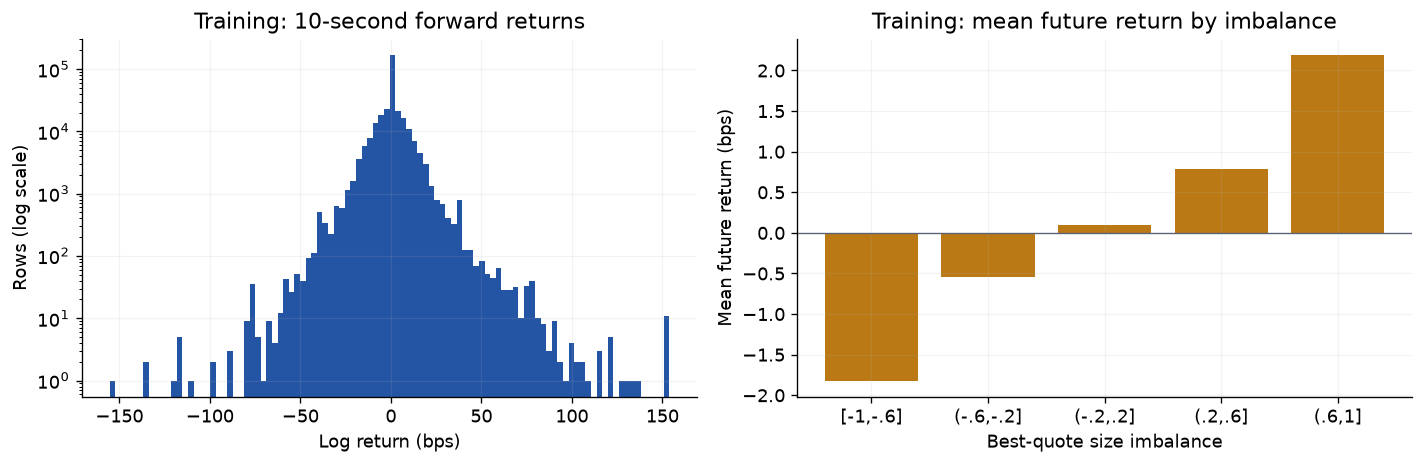

In [31]:
display(train[features + ['target_bps']].describe(percentiles=[.01, .5, .99]).T)
train_eda = train[['imbalance', 'target_bps']].copy()
train_eda['imbalance band'] = pd.cut(train_eda.imbalance, [-1.001, -.6, -.2, .2, .6, 1.001])
imbalance_summary = train_eda.groupby('imbalance band', observed=True)['target_bps'].agg(['count', 'mean', 'std'])
display(imbalance_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train.target_bps, bins=100, color=BLUE, log=True)
axes[0].set(title='Training: 10-second forward returns', xlabel='Log return (bps)', ylabel='Rows (log scale)')
axes[1].bar(range(len(imbalance_summary)), imbalance_summary['mean'], color=GOLD)
axes[1].set_xticks(range(5), ['[-1,-.6]', '(-.6,-.2]', '(-.2,.2]', '(.2,.6]', '(.6,1]'])
axes[1].set(title='Training: mean future return by imbalance', xlabel='Best-quote size imbalance', ylabel='Mean future return (bps)')
axes[1].axhline(0, color=GREY, lw=.8)
fig.tight_layout()
plt.show()

*Left: most 10-second returns are near zero; the logarithmic count axis makes rare large moves visible. Right: larger bid queues relative to ask queues are associated with higher average future returns. These plots use training data only.*

## 5. Model fitting

| Model | Inputs |
|---|---|
| Zero / training mean | No features |
| Lag regression | Recent returns + stock indicators |
| Ridge | All features + stock indicators |
| Random forest | Same inputs, nonlinear effects |

Tune on validation RMSE, then refit on training. Each pipeline learns stock categories and scaling from inner training during tuning, then from full training for final scoring. Scale numeric features and stock indicators for the linear models; leave forest inputs unscaled. Report RMSE, MAE and R²; errors are in basis points.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

input_cols = features + ['symbol']
X_inner = inner_train[input_cols].copy()
X_valid = validation[input_cols].copy()
X_train = train[input_cols].copy()
X_test = test[input_cols].copy()

def make_model(estimator, numeric_features, scale=False):
    preprocess = ColumnTransformer([
        ('numeric', 'passthrough', numeric_features),
        ('stock', OneHotEncoder(drop='first', handle_unknown='ignore',
                               sparse_output=False), ['symbol'])
    ])
    scaler = StandardScaler() if scale else 'passthrough'
    return Pipeline([('preprocess', preprocess), ('scale', scaler), ('model', estimator)])

def rmse(actual, predicted):
    return np.sqrt(mean_squared_error(actual, predicted))

### Tune models

Use a small parameter grid. Keep test data untouched.

In [33]:
lag_model = make_model(LinearRegression(), lag_features, scale=True)
lag_model.fit(X_inner, inner_train['target_bps'])
lag_validation = lag_model.predict(X_valid)
print('Lag regression validation RMSE:', round(rmse(validation['target_bps'], lag_validation), 4))

Lag regression validation RMSE: 5.8344


#### Ridge

In [34]:
alphas = [1, 100, 10_000]
ridge_scores = []
for alpha in alphas:
    ridge_model = make_model(Ridge(alpha=alpha), features, scale=True)
    ridge_model.fit(X_inner, inner_train['target_bps'])
    prediction = ridge_model.predict(X_valid)
    ridge_scores.append(rmse(validation['target_bps'], prediction))

best_alpha = alphas[np.argmin(ridge_scores)]
display(pd.DataFrame({'alpha': alphas, 'validation RMSE (bps)': ridge_scores}))
print('Selected alpha:', best_alpha)

,alpha,validation RMSE (bps)
0,1,5.705316
1,100,5.705263
2,10000,5.701098


Selected alpha: 10000


#### Random forest

In [35]:
depths = [4, 8]
forest_scores = []
for depth in depths:
    forest_model = make_model(RandomForestRegressor(n_estimators=60, max_depth=depth,
        min_samples_leaf=200, max_samples=.5, n_jobs=2, random_state=SEED), features)
    forest_model.fit(X_inner, inner_train['target_bps'])
    prediction = forest_model.predict(X_valid)
    forest_scores.append(rmse(validation['target_bps'], prediction))

best_depth = depths[np.argmin(forest_scores)]
display(pd.DataFrame({'depth': depths, 'validation RMSE (bps)': forest_scores}))
print('Selected depth:', best_depth)

,depth,validation RMSE (bps)
0,4,5.685160
1,8,5.651755


Selected depth: 8


### Refit and score

Compare each period against its zero forecast: train and test volatility differ.

In [36]:
train_predictions = {}
test_predictions = {}
train_predictions['Zero'] = np.zeros(len(train))
test_predictions['Zero'] = np.zeros(len(test))
train_mean = train['target_bps'].mean()
train_predictions['Training mean'] = np.full(len(train), train_mean)
test_predictions['Training mean'] = np.full(len(test), train_mean)

lag_model = make_model(LinearRegression(), lag_features, scale=True)
lag_model.fit(X_train, train['target_bps'])
train_predictions['Lag regression'] = lag_model.predict(X_train)
test_predictions['Lag regression'] = lag_model.predict(X_test)

In [37]:
ridge_model = make_model(Ridge(alpha=best_alpha), features, scale=True)
ridge_model.fit(X_train, train['target_bps'])
train_predictions['Ridge'] = ridge_model.predict(X_train)
test_predictions['Ridge'] = ridge_model.predict(X_test)

forest_model = make_model(RandomForestRegressor(n_estimators=60, max_depth=best_depth,
    min_samples_leaf=200, max_samples=.5, n_jobs=2, random_state=SEED), features)
forest_model.fit(X_train, train['target_bps'])
train_predictions['Random forest'] = forest_model.predict(X_train)
test_predictions['Random forest'] = forest_model.predict(X_test)

In [38]:
# Apply the same four scores to each forecast.
score_rows = []
for name in train_predictions:
    score_rows.append({
        'model': name,
        'train RMSE (bps)': rmse(train['target_bps'], train_predictions[name]),
        'test RMSE (bps)': rmse(test['target_bps'], test_predictions[name]),
        'test MAE (bps)': mean_absolute_error(test['target_bps'], test_predictions[name]),
        'test R2': r2_score(test['target_bps'], test_predictions[name])
    })
model_scores = pd.DataFrame(score_rows).set_index('model')
zero_rmse = model_scores.loc['Zero', 'test RMSE (bps)']
model_scores['test RMSE gain vs zero (%)'] = 100 * (1 - model_scores['test RMSE (bps)'] / zero_rmse)
display(model_scores.round(4))

,train RMSE (bps),test RMSE (bps),test MAE (bps),test R2,test RMSE gain vs zero (%)
model,,,,,
Zero,8.4843,5.1072,2.3262,-0.0001,0.0000
Training mean,8.4832,5.1077,2.4086,-0.0003,-0.0084
Lag regression,8.4381,5.0550,2.4608,0.0203,1.0234
Ridge,8.3017,4.9284,2.8702,0.0687,3.5020
Random forest,8.1940,4.8492,2.8245,0.0984,5.0522


## 6. Analysis and future work

### Model comparison

Lower RMSE and MAE are better.

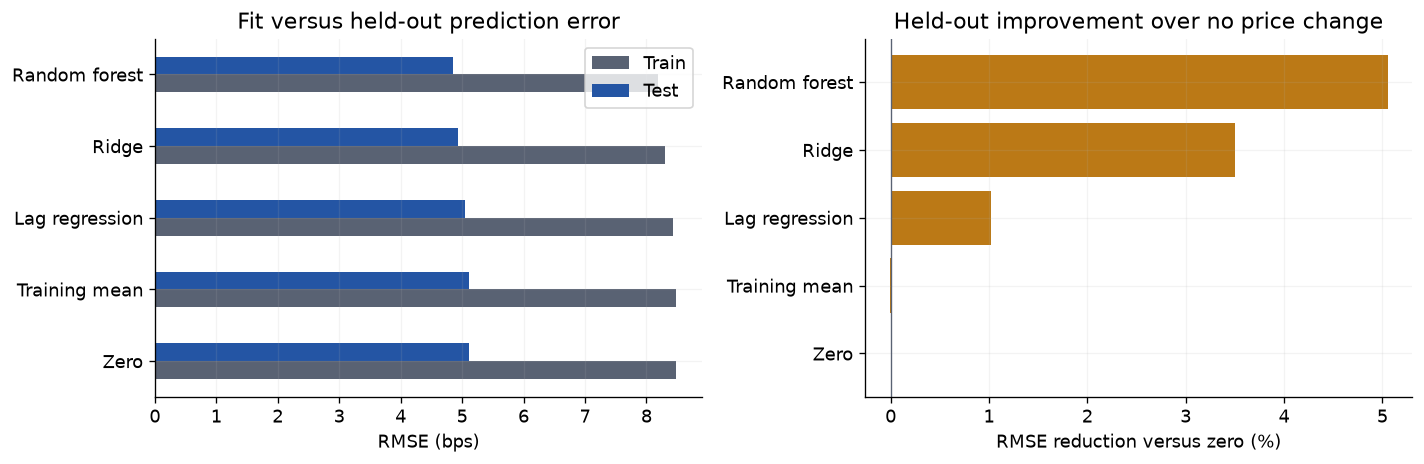

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
model_scores[['train RMSE (bps)', 'test RMSE (bps)']].plot.barh(ax=axes[0], color=[GREY, BLUE])
axes[0].set(title='Fit versus held-out prediction error', xlabel='RMSE (bps)', ylabel='')
axes[0].legend(['Train', 'Test'])
axes[1].barh(model_scores.index, model_scores['test RMSE gain vs zero (%)'], color=GOLD)
axes[1].axvline(0, color=GREY, lw=.8)
axes[1].set(title='Held-out improvement over no price change', xlabel='RMSE reduction versus zero (%)')
fig.tight_layout()
plt.show()

*Lower RMSE is better. The right panel compares test errors with a zero-return forecast: random forest improves RMSE by 5.05%. The test period is less volatile than training. Zero still has the lowest MAE, so model rankings depend on the error measure.*

### Check stability

Compare Ridge with zero by stock, five-minute block and nonoverlapping 10-second observations.

,rows,zero_MSE,ridge_MSE,RMSE gain (%)
symbol,,,,
asset_018,130,18.380594,14.248585,11.954716
asset_038,1966,62.932181,50.747051,10.201514
asset_004,1444,30.443939,24.847338,9.658040
asset_029,2965,52.613107,43.885540,8.669939
asset_016,5575,1.473617,3.278291,-49.152813
asset_034,5514,10.021718,10.821588,-3.914082
asset_017,5452,3.319871,3.532086,-3.146622
asset_013,5321,10.287880,10.942689,-3.133341


10-second-spaced test rows: 18687 | Ridge RMSE: 4.8933 bps | Zero RMSE: 5.0705 bps


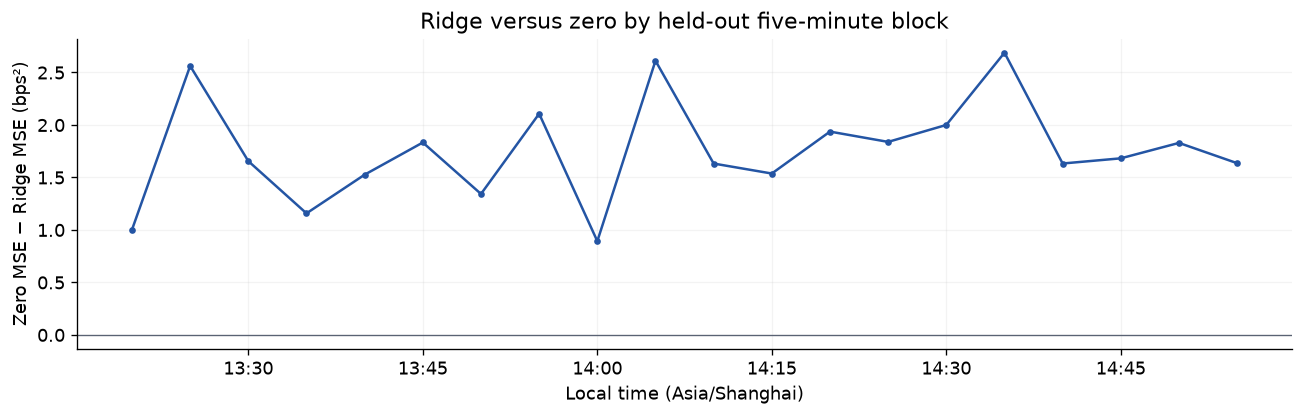

In [40]:
diagnostic = test[['symbol', 'time', 'target_bps', 'session']].copy()
diagnostic['Ridge'] = test_predictions['Ridge']
diagnostic['zero_squared_error'] = diagnostic.target_bps.pow(2)
diagnostic['ridge_squared_error'] = (diagnostic.target_bps - diagnostic.Ridge).pow(2)
stock_scores = diagnostic.groupby('symbol', observed=True).agg(
    rows=('target_bps', 'size'), zero_MSE=('zero_squared_error', 'mean'), ridge_MSE=('ridge_squared_error', 'mean'))
stock_scores['RMSE gain (%)'] = 100 * (1 - np.sqrt(stock_scores.ridge_MSE / stock_scores.zero_MSE))
display(pd.concat([stock_scores.nlargest(4, 'RMSE gain (%)'), stock_scores.nsmallest(4, 'RMSE gain (%)')]))
nonoverlap = diagnostic.loc[diagnostic.time.dt.second.mod(HORIZON).eq(0)]
print('10-second-spaced test rows:', len(nonoverlap), '| Ridge RMSE:',
      f'{rmse(nonoverlap.target_bps, nonoverlap.Ridge):.4f} bps | Zero RMSE:',
      f'{rmse(nonoverlap.target_bps, np.zeros(len(nonoverlap))):.4f} bps')

diagnostic['block'] = diagnostic.time.dt.floor('5min')
diagnostic['MSE gain'] = diagnostic.zero_squared_error - diagnostic.ridge_squared_error
block_gain = diagnostic.groupby('block')['MSE gain'].mean()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(block_gain.index, block_gain, color=BLUE, marker='o', ms=3)
ax.axhline(0, color=GREY, lw=.8)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=day.tz))
ax.set(title='Ridge versus zero by held-out five-minute block', xlabel='Local time (Asia/Shanghai)',
       ylabel='Zero MSE − Ridge MSE (bps²)')
fig.tight_layout()
plt.show()

*Each point is a five-minute test block. Above zero means Ridge has lower mean squared error than the zero-return forecast. All 20 blocks improve, but the stock-level table shows that 10 of 49 stocks do not.*

### Findings

In [41]:
best_name = model_scores['test RMSE (bps)'].idxmin()
best_rmse = model_scores.loc[best_name, 'test RMSE (bps)']
best_gain = model_scores.loc[best_name, 'test RMSE gain vs zero (%)']
pair = pair_corr.index[0]
buy_share = direction_summary.loc['Buyer tick', 'fraction of classified']
rejections = (return_tests[['p classical', 'p Holm']] < .05).sum()
stocks_improved = (stock_scores['RMSE gain (%)'] > 0).sum()
blocks_improved = (block_gain > 0).sum()

print('Highest opening VWAP:', vwap_winner, round(vwap.iloc[0]['VWAP_CNY'], 4), 'CNY')
print('Highest volume:', total_volume.index[0])
print('Strongest volume correlation:', pair, round(pair_corr.iloc[0], 3))
print('Quote mean spread:', round(spread_comparison.iloc[0], 5), 'CNY')
print('Trade-time median spread:', round(spread_comparison['trade-time median (CNY)'], 5), 'CNY')
print(f'Classified ticks: {buy_share:.2%} buy, {1 - buy_share:.2%} sell')
print('Mean-return rejections (raw / Holm):', rejections.tolist())
print(f'Best RMSE: {best_name}, {best_rmse:.4f} bps ({best_gain:.2f}% below zero)')
print('Lowest MAE: Zero,', round(model_scores.loc['Zero', 'test MAE (bps)'], 4), 'bps')
print(f'Ridge improves {stocks_improved}/{len(stock_scores)} stocks and',
      f'{blocks_improved}/{len(block_gain)} time blocks.')
print('One day cannot establish trading profits.')

Highest opening VWAP: asset_016 224.5143 CNY
Highest volume: asset_040
Strongest volume correlation: ('asset_027', 'asset_006') 0.911
Quote mean spread: 0.01434 CNY
Trade-time median spread: 0.01 CNY
Classified ticks: 55.23% buy, 44.77% sell
Mean-return rejections (raw / Holm): [2, 1]
Best RMSE: Random forest, 4.8492 bps (5.05% below zero)
Lowest MAE: Zero, 2.3262 bps
Ridge improves 39/49 stocks and 20/20 time blocks.
One day cannot establish trading profits.


### Next steps

- Test more days and market conditions.
- Verify duplicates, event order and quote freshness.
- Compare the same model with and without trade flow.
- Add execution rules and costs before claiming trading profits.

### References

[As-of matching](https://pandas.pydata.org/docs/reference/api/pandas.merge_asof.html) · [Holm correction](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html) · [Time-series validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html)

### Checks

In [42]:
assert np.isclose(volume_30m.to_numpy().sum(), trade.trade_qty.sum())
assert len(aligned) == len(focus_trade)
assert aligned.loc[aligned.quote_time.notna(), 'quote_time'].le(aligned.loc[aligned.quote_time.notna(), 'time']).all()
assert train.target_time.max() < test.time.min()
assert inner_train.target_time.max() < validation.time.min()
assert model_data.time.lt(model_data.target_time).all()
print('Checks passed: volume totals, join cardinality, quote timing, 10-second targets and purged splits.')

Checks passed: volume totals, join cardinality, quote timing, 10-second targets and purged splits.
